# Fit of the layer 1 models

This notebook checks how well the layer 1 models of the traffic generator fit the data: it compares the hourly counts they generate with the real counts of each junction.

It deliberately does not cover layer 2, which splits hourly totals across roads and turns. The raw data has no information on roads or directions, so layer 2 cannot be tested against it. For a description of the data itself, see `kaggle_data_eda.ipynb`.

Run `uv run python scripts/download_kaggle_data.py` first to get the data. The logic lives in the `trafficgen` package. The notebook only calls it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from trafficgen import MeanProfileModel, StatisticalCountModel, load_config, load_counts
from trafficgen.validation import realism_scores, sample_many, statistics_table

CONFIG_PATH = Path("../configs/traffic.toml")
RUNS = 200
SEED = 0

REAL = {"color": "#2a78d6", "label": "Real", "linestyle": "-"}
STATISTICAL = {"color": "#eb6834", "label": "Statistical model", "linestyle": "--"}
BASELINE = {"color": "#1baf7a", "label": "Baseline", "linestyle": ":"}

plt.rcParams.update(
    {
        "figure.dpi": 90,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "lines.linewidth": 1.8,
        "legend.frameon": False,
    }
)


def junction_grid(title, ylabel, xlabel):
    """Create one panel per junction with independent y axes."""
    figure, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True, layout="constrained")
    figure.suptitle(title, x=0.01, ha="left", fontsize=13)
    figure.supylabel(ylabel, fontsize=10, color="#52514e")
    figure.supxlabel(xlabel, fontsize=10, color="#52514e")
    return figure, dict(zip(counts, axes.flat, strict=True))


def add_legend(figure):
    """Add one legend above the panels of a figure."""
    handles, labels = figure.axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper right", ncols=len(labels))

## 1. The models

On the `log(1 + count)` scale, the model is:

```
y[t] = level[t] + profile[weekday, hour] + noise[t]
```

- **Level:** a four week moving average, centred on each hour. Near the start and end of the data, the window only covers the hours that exist, at least two weeks. Inside the data period the level follows the fitted growth. Outside it, the level stays flat, because there is too little data to extrapolate growth or separate it from the time of year.
- **Profile:** the average per weekday and hour.
- **Noise:** random one week blocks of the real remaining noise (a block bootstrap), which keeps bursts over several days.

The baseline is simpler: the average per weekday and hour with Poisson noise, ignoring growth. Sources are listed in the docstrings of `trafficgen.models`.

In [2]:
config = load_config(CONFIG_PATH)
counts = {junction.id: load_counts(junction.data).astype(float) for junction in config.junctions}

statistical = {junction: StatisticalCountModel().fit(series) for junction, series in counts.items()}
baseline = {junction: MeanProfileModel().fit(series) for junction, series in counts.items()}

### Are the junctions independent?

Raw counts correlate strongly, but mostly because of shared growth and shared daily rhythm. What remains after removing them is what independent models would miss.

In [3]:
raw = pd.DataFrame(counts).corr().round(2)
remaining = pd.DataFrame({j: model.noise_ for j, model in statistical.items()}).corr().round(2)
pd.concat({"raw counts": raw, "remaining noise": remaining}, axis=1)

raw counts                   remaining noise                  
           J1    J2    J3    J4              J1    J2    J3    J4
J1       1.00  0.87  0.53  0.59            1.00  0.25  0.19  0.18
J2       0.87  1.00  0.43  0.40            0.25  1.00  0.15  0.07
J3       0.53  0.43  1.00  0.49            0.19  0.15  1.00  0.19
J4       0.59  0.40  0.49  1.00            0.18  0.07  0.19  1.00

The noise correlations are low, so modelling junctions independently is a reasonable simplification. The data cannot show how the junctions are connected: it has no road information, and crossing a block takes far less than the hourly resolution.

These correlations use every hour that a pair of junctions shares. The EDA notebook only uses the first half of 2017, when all four junctions have data, so its values differ slightly (J1 and J2: 0.83 there, 0.87 here).

## 2. Generated traffic compared with the real data

Every model below generates traffic for the same hours as the real data, using 200 random seeds where more than one is needed. These checks use the training data, so they show the quality of the fit. Section 3 checks months the model has not seen.

In [4]:
samples = {
    "Statistical model": {
        j: sample_many(m, counts[j].index, RUNS, seed=SEED) for j, m in statistical.items()
    },
    "Baseline": {j: sample_many(m, counts[j].index, RUNS, seed=SEED) for j, m in baseline.items()},
}

### One example week

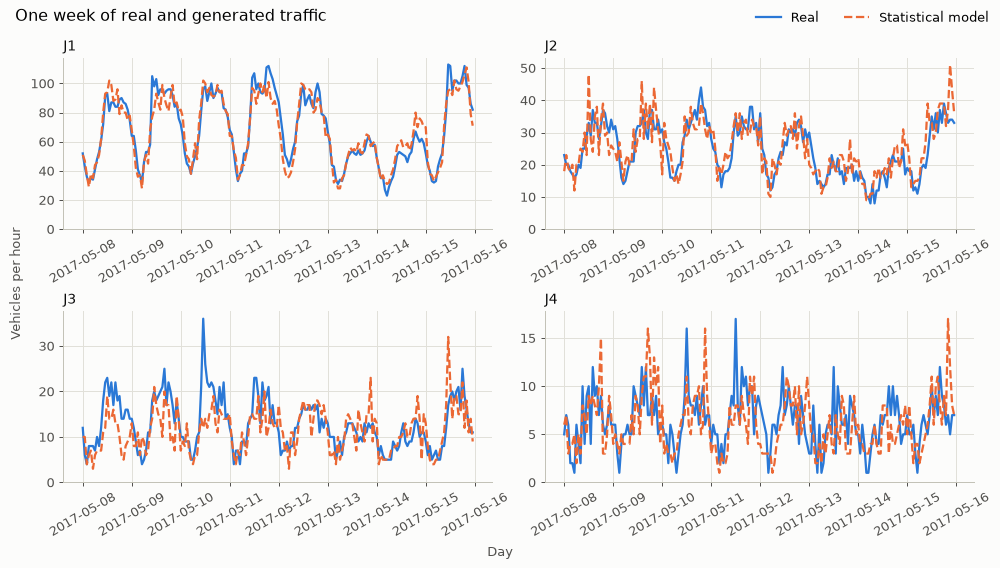

In [5]:
WEEK_START, WEEK_END = "2017-05-08", "2017-05-15"

figure, panels = junction_grid("One week of real and generated traffic", "Vehicles per hour", "Day")
for junction, axis in panels.items():
    real = counts[junction].loc[WEEK_START:WEEK_END]
    generated = samples["Statistical model"][junction].loc[WEEK_START:WEEK_END, 0]
    axis.plot(real.index, real.to_numpy(), **REAL)
    axis.plot(generated.index, generated.to_numpy(), **STATISTICAL)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True, rotation=30)
add_legend(figure)
plt.show()

### Daily and weekly profiles

The baseline matches the average day by construction, so its line is hidden behind the others.

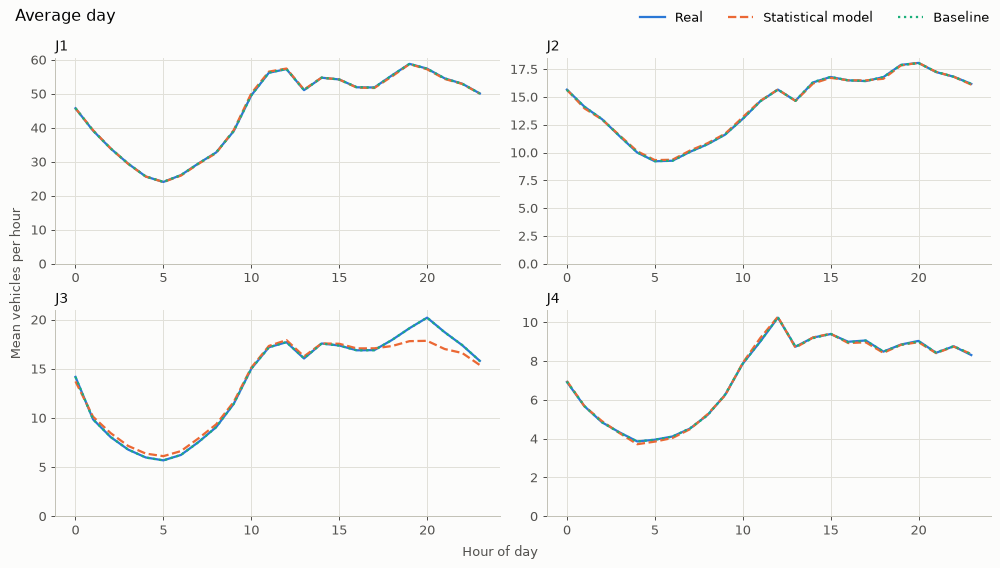

In [6]:
def daily_profile(series):
    """Average a series for each hour of the day."""
    return series.groupby(pd.DatetimeIndex(series.index).hour).mean()


figure, panels = junction_grid("Average day", "Mean vehicles per hour", "Hour of day")
for junction, axis in panels.items():
    axis.plot(daily_profile(counts[junction]), **REAL)
    for name, style in (("Statistical model", STATISTICAL), ("Baseline", BASELINE)):
        axis.plot(daily_profile(samples[name][junction].mean(axis=1)), **style)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True)
add_legend(figure)
plt.show()

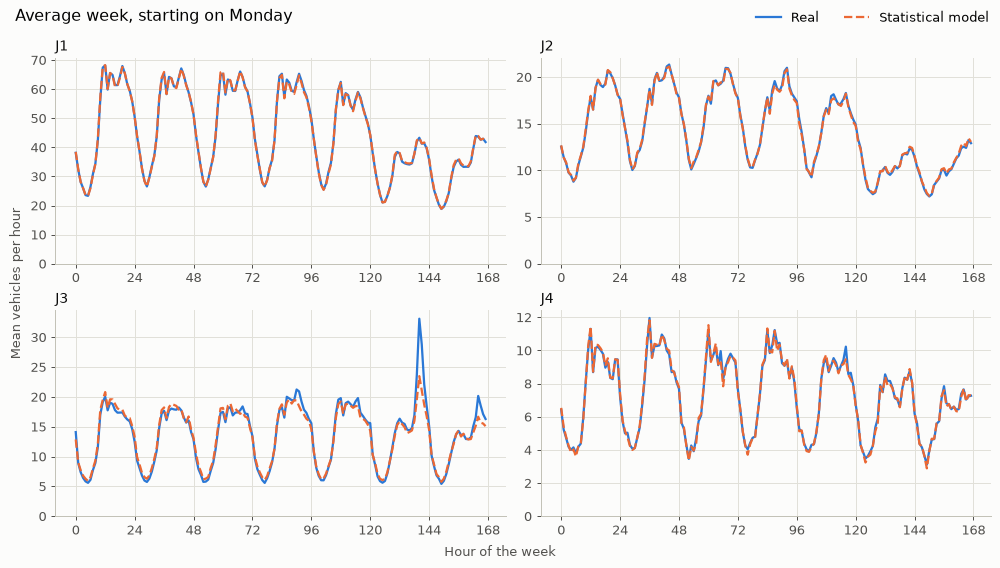

In [7]:
def weekly_profile(series):
    """Average a series for each hour of the week."""
    index = pd.DatetimeIndex(series.index)
    return series.groupby(index.day_of_week * 24 + index.hour).mean()


figure, panels = junction_grid(
    "Average week, starting on Monday", "Mean vehicles per hour", "Hour of the week"
)
for junction, axis in panels.items():
    generated = samples["Statistical model"][junction].mean(axis=1)
    axis.plot(weekly_profile(counts[junction]), **REAL)
    axis.plot(weekly_profile(generated), **STATISTICAL)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_xticks(range(0, 169, 24))
    axis.set_ylim(bottom=0)
    axis.tick_params(axis="x", labelbottom=True)
add_legend(figure)
plt.show()

### Distributions

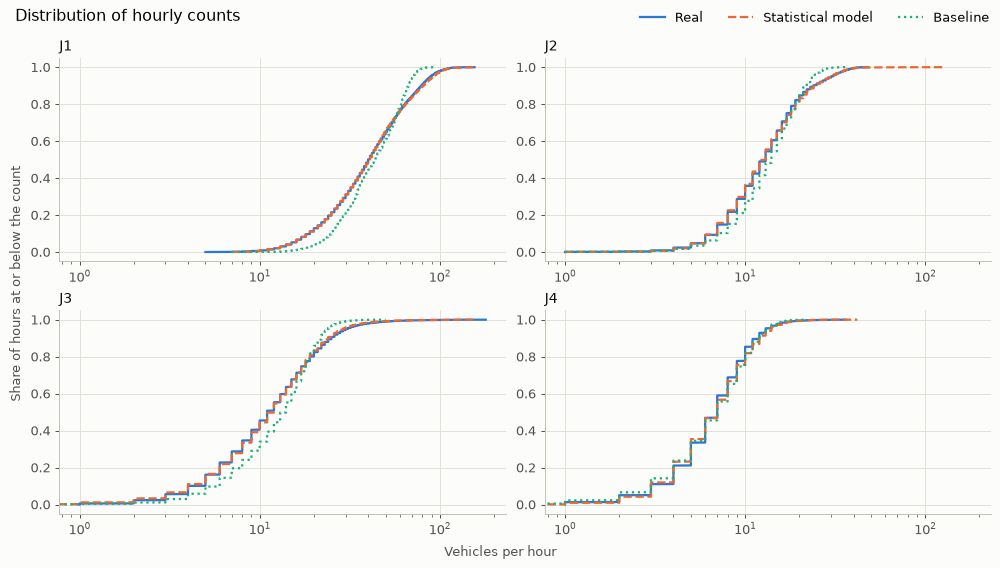

In [8]:
def empirical_cdf(values):
    """Return the sorted values and their cumulative shares."""
    ordered = np.sort(values)
    return ordered, np.arange(1, len(ordered) + 1) / len(ordered)


figure, panels = junction_grid(
    "Distribution of hourly counts", "Share of hours at or below the count", "Vehicles per hour"
)
for junction, axis in panels.items():
    axis.plot(*empirical_cdf(counts[junction].to_numpy()), **REAL)
    for name, style in (("Statistical model", STATISTICAL), ("Baseline", BASELINE)):
        axis.plot(*empirical_cdf(samples[name][junction][0].to_numpy()), **style)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.tick_params(axis="x", labelbottom=True)
    axis.set_xscale("log")
add_legend(figure)
plt.show()

### Autocorrelation

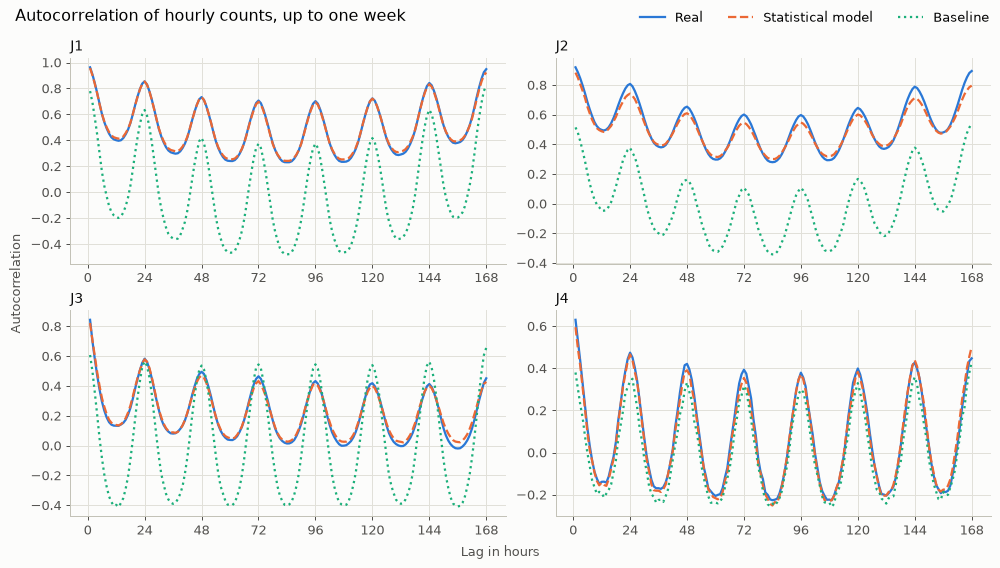

In [9]:
LAGS = range(1, 169)


def autocorrelations(series):
    """Return the autocorrelation of a series at every lag up to one week."""
    return [series.autocorr(lag) for lag in LAGS]


figure, panels = junction_grid(
    "Autocorrelation of hourly counts, up to one week", "Autocorrelation", "Lag in hours"
)
for junction, axis in panels.items():
    axis.plot(LAGS, autocorrelations(counts[junction]), **REAL)
    for name, style in (("Statistical model", STATISTICAL), ("Baseline", BASELINE)):
        axis.plot(LAGS, autocorrelations(samples[name][junction][0]), **style)
    axis.set_title(junction, loc="left", fontsize=11)
    axis.set_xticks(range(0, 169, 24))
    axis.tick_params(axis="x", labelbottom=True)
add_legend(figure)
plt.show()

### Statistical comparison

Significance tests would flag almost any small difference with this many autocorrelated hours, so the tables report the sizes of differences instead of p-values.

- **wasserstein:** average vehicles per hour separating the two distributions. Lower is better.
- **ks:** largest gap between the two cumulative distributions, from 0 to 1. Lower is better.
- **daily and weekly profile error:** average profile difference relative to the mean count. Lower is better.
- **coverage_80:** share of real hours that lie between the 10th and 90th percentile of the generated values for that hour. It should be close to 0.80. With few runs these percentiles are estimated too close together, which is why the notebook uses 200 runs.

In [10]:
pd.DataFrame(
    {
        (name, junction): realism_scores(counts[junction], samples[name][junction])
        for name in samples
        for junction in counts
    }
).T.round(3)

wasserstein     ks  daily_profile_error  \
Statistical model J1        0.424  0.012                0.007   
                  J2        0.231  0.016                0.010   
                  J3        0.460  0.021                0.045   
                  J4        0.188  0.029                0.024   
Baseline          J1        5.724  0.104                0.005   
                  J2        1.423  0.078                0.009   
                  J3        2.384  0.114                0.009   
                  J4        0.335  0.037                0.022   

                      weekly_profile_error  coverage_80  
Statistical model J1                 0.013        0.832  
                  J2                 0.020        0.865  
                  J3                 0.066        0.838  
                  J4                 0.056        0.866  
Baseline          J1                 0.013        0.304  
                  J2                 0.023        0.650  
                  J3                 0.023        0.613  
                  J4                 0.058        0.904

Real and generated statistics per junction for the statistical model, with the range covering 90% of generated series:

In [11]:
pd.concat(
    {
        junction: statistics_table(counts[junction], samples["Statistical model"][junction])
        for junction in counts
    }
).round(2)

real  generated  generated_p05  generated_p95
J1 mean       45.05      45.06          44.73          45.49
   std        23.01      23.09          22.65          23.60
   p50        40.00      40.53          40.00          41.00
   p90        79.00      79.88          79.00          81.00
   p99       108.09     106.44         104.00         110.00
   max       156.00     152.76         135.95         173.05
   acf_1h      0.96       0.95           0.95           0.96
   acf_24h     0.85       0.85           0.84           0.86
   acf_168h    0.95       0.93           0.92           0.94
J2 mean       14.25      14.27          14.13          14.38
   std         7.40       7.48           7.25           7.83
   p50        13.00      12.79          12.00          13.00
   p90        24.00      24.49          24.00          25.00
   p99        38.00      37.90          37.00          39.00
   max        48.00      72.80          50.95         128.05
   acf_1h      0.92       0.87           0.86           0.88
   acf_24h     0.81       0.76           0.72           0.78
   acf_168h    0.89       0.82           0.77           0.85
J3 mean       13.69      13.56          13.02          14.06
   std        10.44       9.53           8.63          10.27
   p50        11.00      11.70          11.00          12.00
   p90        25.00      24.31          23.00          26.00
   p99        51.00      47.01          42.00          52.00
   max       180.00     145.57         107.95         188.05
   acf_1h      0.84       0.82           0.80           0.84
   acf_24h     0.58       0.58           0.55           0.62
   acf_168h    0.45       0.43           0.38           0.47
J4 mean        7.25       7.24           7.08           7.38
   std         3.52       3.54           3.36           3.72
   p50         7.00       6.99           7.00           7.00
   p90        12.00      11.98          12.00          12.00
   p99        18.00      17.40          16.00          18.57
   max        36.00      36.52          26.95          48.05
   acf_1h      0.63       0.56           0.53           0.60
   acf_24h     0.47       0.45           0.42           0.48
   acf_168h    0.45       0.47           0.43           0.50

### Results

The statistical model reproduces the real distribution far better than the baseline, because the baseline ignores growth and treats every hour as independent:

- **Distribution:** the Wasserstein distance is at most 0.46 vehicles per hour, against up to 5.72 for the baseline.
- **Spread:** the coverage of the 80% range is 0.83 to 0.87, against 0.30 to 0.90 for the baseline. Slightly above 0.80 means the generated spread is a little too wide.
- **Autocorrelation:** it follows the real curves closely, including the daily and weekly cycles. The baseline falls well below them on J1 and J2. On J3 and J4 the gap is largest at one hour, and on J3 the baseline overstates the correlation at one week.

Averages are not where the baseline loses. It matches average profiles by construction, so it is hidden behind the other lines in the average day chart, and its profile errors on J3 are lower.

Known limits of the statistical model:

- **J3 bursts:** the largest bursts are underestimated (std 9.53 against 10.44, 99th percentile 47 against 51). The Saturday evening peak is the clearest case, at about 24 against 33 vehicles per hour. Averaging on the log scale gives such rare bursts less weight.
- **J2 extreme hours:** the highest generated hours go beyond anything in the data (a typical maximum of 73 against 48), because noise from quiet hours can land on busy ones. They are rare: the 99th percentile still matches at 38.
- **Autocorrelation:** it is slightly low on J2 (one hour 0.87 against 0.92, one week 0.82 against 0.89). The real value also falls outside the generated range on J1 at one week (0.93 against 0.95) and on J4 at one hour (0.56 against 0.63).
- **Fit only:** these checks use the training data, so they show how well the model fits. Section 3 checks unseen months.

## 3. Unseen months

The checks above use the same data the models were fitted on. Here, each model is fitted on the data up to the end of March 2017 and generates April to June 2017, which is then compared with the real counts of those months.

Outside its fitted period, the statistical model holds the level flat, so this also shows how far that assumption carries. J4 only has data from January 2017, so its model is fitted on three months.

In [12]:
TEST_START = "2017-04-01"

MODELS = {"Statistical model": StatisticalCountModel, "Baseline": MeanProfileModel}

holdout = {}
for name, model_class in MODELS.items():
    for junction, series in counts.items():
        train = series[series.index < TEST_START]
        test = series[series.index >= TEST_START]
        model = model_class().fit(train)
        holdout[(name, junction)] = realism_scores(test, sample_many(model, test.index, RUNS, SEED))
pd.DataFrame(holdout).T.round(3)

wasserstein     ks  daily_profile_error  \
Statistical model J1        3.010  0.083                0.049   
                  J2        2.039  0.135                0.090   
                  J3        2.136  0.094                0.129   
                  J4        0.634  0.073                0.097   
Baseline          J1       27.470  0.442                0.402   
                  J2       11.887  0.579                0.488   
                  J3        4.581  0.216                0.260   
                  J4        0.599  0.079                0.082   

                      weekly_profile_error  coverage_80  
Statistical model J1                 0.059        0.803  
                  J2                 0.104        0.837  
                  J3                 0.185        0.822  
                  J4                 0.152        0.780  
Baseline          J1                 0.402        0.010  
                  J2                 0.488        0.065  
                  J3                 0.266        0.610  
                  J4                 0.159        0.875

On unseen months the statistical model is clearly worse than on its training data, but still close to the real traffic:

- **Distribution:** the Wasserstein distance is 0.63 to 3.01 vehicles per hour, against up to 27.47 for the baseline.
- **Spread:** the coverage of the 80% range is 0.78 to 0.84, against as low as 0.01 for the baseline.
- **Profiles:** the weekly profile error grows to 0.06 to 0.19, as the level and rhythm of traffic keep changing after the fitted period.

The baseline fails because it averages the whole history, including the much quieter early months, so it generates far too little traffic for 2017. J4 is the exception: its three training months show almost no growth, so the baseline does about as well as the statistical model there.

Holding the level flat is therefore reasonable for a few months past the data, but the error grows with distance, since growth is not extrapolated.